# Algorithmes d'ensemble sur cas concret — version 3 (en cours)
*Formation Machine Learning (BI105), Philippe Bonny@2021-2026*

> Cette version met en place un protocole d'évaluation sans fuite : jeu de test final isolé, prétraitement appris dans chaque pli de validation croisée et stratégie CV commune à tous les modèles.

<img src="https://drive.google.com/thumbnail?id=1a2AqvWlP9fJhsJGqpFH0HTDlEkLjs-6J&sz=w700"><br>
<i>source image : https://www.homes.com/neighborhood-search/ames-ia/</i>

> **Business Case** : Estimer le prix de maisons résidentielles dans la ville d'Ames, Iowa à partir de leur description.

**Description des données** :<br>
The Ames Housing Dataset is a well-known dataset in the field of machine learning and data analysis. It contains various features and attributes of residential homes in Ames, Iowa, USA. The dataset is often used for regression tasks, particularly for predicting housing prices.

Here are some key details about the Ames Housing Dataset:

- Number of Instances: The dataset consists of 2,930 instances or observations.
- Number of Features: There are 79 different features or variables that describe various aspects of the residential properties.
- Target Variable: The target variable in the dataset is the "SalePrice," representing the sale price of the houses.
- Data Types: The features include both numerical and categorical variables, covering a wide range of aspects such as lot size, number of rooms, location, construction, and more. 
 
<br>
The Ames Housing Dataset is widely used in the machine learning community for tasks such as regression modeling, feature engineering, and predictive analytics related to housing prices. It serves as a valuable resource for developing and testing machine learning algorithms and techniques in the real estate domain.<br>
Source : https://www.kaggle.com/datasets/shashanknecrothapa/ames-housing-dataset

## UTILITAIRES

### compute

In [0]:
vm="Azure Standard D16ds_v5 (16 cores, 16Gb)"
print(f"VM : {vm}")

import os
print("DATABRICKS_RUNTIME_VERSION:", os.environ.get('DATABRICKS_RUNTIME_VERSION', None))
!python -V

# Parallélisme : un modèle par cœur de validation, au maximum un par pli
CV_FOLDS = 10
N_CORES = os.cpu_count() or 1
N_JOBS_MODEL = 1
N_JOBS_CV = min(CV_FOLDS, N_CORES)
N_JOBS_GP = N_CORES
PRIMARY_SCORING = "neg_root_mean_squared_error"
print(f"Parallélisme : {N_CORES} cœurs, CV={N_JOBS_CV}, modèle={N_JOBS_MODEL}, GP={N_JOBS_GP}")

VM : Azure Standard D16ds_v5 (16 cores, 16Gb)
DATABRICKS_RUNTIME_VERSION: 16.4
Python 3.12.3
Parallélisme : 16 cœurs, CV=10, modèle=1, GP=16


In [0]:
%pip install scikit-optimize xgboost

  Using cached scikit_optimize-0.10.2-py2.py3-none-any.whl.metadata (9.7 kB)
  Using cached pyaml-26.7.0-py3-none-any.whl.metadata (12 kB)
Using cached scikit_optimize-0.10.2-py2.py3-none-any.whl (107 kB)
Using cached pyaml-26.7.0-py3-none-any.whl (27 kB)
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


### librairies

In [0]:
%pip freeze | grep 'scikit-learn\|scikit-optimize\|xgboost'

scikit-learn==1.4.2
scikit-optimize==0.10.2
xgboost==2.0.3
xgboost-ray==0.1.19


### fonctions

In [0]:
# fonctions d'affichage graphique
import matplotlib.pyplot as plt

def show_hist0(x, name=False, bins=50):
    plt.hist(x, bins=50)
    plt.xlabel(name) if name else None
    plt.show()

def show_hist(y, y_pred, test=True):
    title = "TEST" if test else "TRAIN"
    plt.hist(y_pred, bins=50, label='Predictions', alpha=1)
    plt.hist(y, bins=50, label='Originales', alpha=0.5, color='grey')
    plt.legend()
    plt.title(f"Histogramme des valeurs prédites et vraies pour le {title}")
    plt.show()

def show_hist2(y_train, y_train_pred, y_test, y_test_pred):
    fig, (ax0, ax1) = plt.subplots(nrows=1, ncols=2, figsize=[12, 4])
    ax0.hist(y_train_pred, bins=50, label='Predictions', alpha=0.9, color='cornflowerblue')
    ax0.hist(y_train, bins=50, label='Originales', alpha=0.5, color='grey')
    ax0.legend()
    ax0.set_xlabel("Prix de vente ($)")
    ax0.set_title("TRAIN")

    ax1.hist(y_test_pred, bins=50, label='Predictions', alpha=0.7, color="green")
    ax1.hist(y_test, bins=50, label='Originales', alpha=0.7, color='grey')
    ax1.legend()
    ax1.set_xlabel("Prix de vente ($)")
    ax1.set_title("TEST")
    
    fig.tight_layout()
    plt.suptitle("Histogramme des valeurs prédites et vraies", y=1.05, fontweight='bold')
    display(plt.gcf())
    plt.close()

In [0]:
# courbe d'apprentissage
from sklearn.model_selection import learning_curve
import numpy as np

def show_learning_curve(model_fitted, X, y, scoring='r2', cv=CV_FOLDS, n_jobs=N_JOBS_CV):
    train_sizes, train_scores, val_scores = \
    learning_curve(estimator=model_fitted,
                  X=X,
                  y=y,
                   # échantillonage du jeux de données
                   # d'entrainement 1% à 100% (10 valeurs)
                  train_sizes=np.linspace(0.1,1.0,10),
                   # utilisation d'un CV à 10 partitions
                  cv=cv,
                  scoring=scoring,
                   # pour le parallélisme
                   n_jobs=n_jobs
                  )

    # Préparation des données pour l'affichage
    train_mean = np.mean(train_scores, axis=1)
    train_std = np.std(train_scores, axis=1)
    val_mean = np.mean(val_scores, axis=1)
    val_std = np.std(val_scores, axis=1)

    # Affichage de la courbe d'entrainement : 
    # train_score_moyen = f( taille des données train )
    plt.plot(train_sizes, train_mean,
            color='blue', marker='o',
            markersize=5, label='train')

    # Affichage des écarts types sur les scores de la CV
    # correspondants
    plt.fill_between(train_sizes,
                    train_mean + train_std,
                    train_mean - train_std,
                    alpha=0.15, color='blue')

    # Affichage de la courbe de validation :
    plt.plot(train_sizes, val_mean,
            color='green', linestyle='--',
            marker='s', markersize=5, 
            label='validation')

    plt.fill_between(train_sizes,
                    val_mean + val_std,
                    val_mean - val_std,
                    alpha=0.15, color='green')

    # Paramètres d'affichages généraux
    plt.style.use('seaborn-v0_8')
    plt.title('Courbes d\'apprentissage du modèle')
    plt.xlabel('Nombre d\'échantillons d\'entrainement')
    plt.ylabel(f'Performance ({scoring})')
    plt.legend(loc='lower right')
    #plt.ylim(ylim_min, ylim_max)
    plt.tight_layout
    #plt.savefig('images/06_05.png', dpi=300)
    display(plt.gcf())
    plt.close()
    

### divers

In [0]:
import mlflow
mlflow.autolog(disable=True)

# EXERCICE

Pour résoudre ce cas :
- Créer un premier modèle Random Forest
- Créer un premier modèle Random Forest
- Utiliser un grid search pour améliorer les réglages
- Faire de même avec un Randomized Search
- Tester ensuite une optimisation bayésienne
- Reprendre les même opérations avec un XGBoost

# SOLUTION

## Données du LAB
- source : https://www.kaggle.com/datasets/prevek18/ames-housing-dataset*

In [0]:
import pandas as pd
data = pd.read_csv('./AmesHousing.csv')

In [0]:
data.shape

(2930, 82)

In [0]:
data.head()

,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,Condition 1,Condition 2,Bldg Type,House Style,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Roof Style,Roof Matl,Exterior 1st,Exterior 2nd,Mas Vnr Type,Mas Vnr Area,Exter Qual,Exter Cond,Foundation,Bsmt Qual,Bsmt Cond,Bsmt Exposure,BsmtFin Type 1,BsmtFin SF 1,BsmtFin Type 2,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,...,Central Air,Electrical,1st Flr SF,2nd Flr SF,Low Qual Fin SF,Gr Liv Area,Bsmt Full Bath,Bsmt Half Bath,Full Bath,Half Bath,Bedroom AbvGr,Kitchen AbvGr,Kitchen Qual,TotRms AbvGrd,Functional,Fireplaces,Fireplace Qu,Garage Type,Garage Yr Blt,Garage Finish,Garage Cars,Garage Area,Garage Qual,Garage Cond,Paved Drive,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,6,5,1960,1960,Hip,CompShg,BrkFace,Plywood,Stone,112.0,TA,TA,CBlock,TA,Gd,Gd,BLQ,639.0,Unf,0.0,441.0,1080.0,...,Y,SBrkr,1656,0,0,1656,1.0,0.0,1,0,3,1,TA,7,Typ,2,Gd,Attchd,1960.0,Fin,2.0,528.0,TA,TA,P,210,62,0,0,0,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Feedr,Norm,1Fam,1Story,5,6,1961,1961,Gable,CompShg,VinylSd,VinylSd,None,0.0,TA,TA,CBlock,TA,TA,No,Rec,468.0,LwQ,144.0,270.0,882.0,...,Y,SBrkr,896,0,0,896,0.0,0.0,1,0,2,1,TA,5,Typ,0,NaN,Attchd,1961.0,Unf,1.0,730.0,TA,TA,Y,140,0,0,0,120,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,6,6,1958,1958,Hip,CompShg,Wd Sdng,Wd Sdng,BrkFace,108.0,TA,TA,CBlock,TA,TA,No,ALQ,923.0,Unf,0.0,406.0,1329.0,...,Y,SBrkr,1329,0,0,1329,0.0,0.0,1,1,3,1,Gd,6,Typ,0,NaN,Attchd,1958.0,Unf,1.0,312.0,TA,TA,Y,393,36,0,0,0,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,7,5,1968,1968,Hip,CompShg,BrkFace,BrkFace,None,0.0,Gd,TA,CBlock,TA,TA,No,ALQ,1065.0,Unf,0.0,1045.0,2110.0,...,Y,SBrkr,2110,0,0,2110,1.0,0.0,2,1,3,1,Ex,8,Typ,2,TA,Attchd,1968.0,Fin,2.0,522.0,TA,TA,Y,0,0,0,0,0,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,Gilbert,Norm,Norm,1Fam,2Story,5,5,1997,1998,Gable,CompShg,VinylSd,VinylSd,None,0.0,TA,TA,PConc,Gd,TA,No,GLQ,791.0,Unf,0.0,137.0,928.0,...,Y,SBrkr,928,701,0,1629,0.0,0.0,2,1,3,1,TA,6,Typ,1,TA,Attchd,1997.0,Fin,2.0,482.0,TA,TA,Y,212,34,0,0,0,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


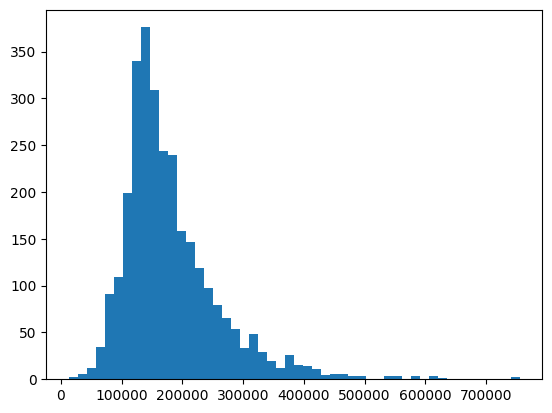

In [0]:
import matplotlib.pyplot as plt
plt.hist(data['SalePrice'], bins=50, label='SalePrice')
plt.show()

> In faudra prendre en compte le fait qu'il y a des valeurs extrêmes mais peu nombreuses, ce qui a un impact sur le choix du critère de sélection du modèle (*hyper-parameter tuning*)

In [0]:
# data profile Databricks
# display(data)

## Prétraitement

> Le découpage entraînement/test est effectué sur les données brutes. La création de variables, l'imputation et l'encodage sont regroupés dans un pipeline scikit-learn : ils sont donc réappris uniquement sur la partie entraînement de chaque pli de validation croisée. Les valeurs catégorielles manquantes sont représentées par la catégorie explicite `Missing`.

### features
- source : modifié d'après https://github.com/maym5/ames-housing/blob/main/kaggle_housing.ipynb

In [0]:
from sklearn.base import BaseEstimator, TransformerMixin


class AmesFeatureEngineer(BaseEstimator, TransformerMixin):
    # Ajoute les variables métier sans apprendre d'information sur les données.
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        df = X.copy()
        df = df.drop(
            columns=['PID', 'Alley', 'Fence', 'Misc Feature', 'Pool QC'],
            errors='ignore'
        )
        df['totalSF'] = df['1st Flr SF'] + df['2nd Flr SF'] + df['Total Bsmt SF']
        df['finishedSF'] = df['totalSF'] - df['Bsmt Unf SF']
        df['qualitySF'] = df['totalSF'] - df['Low Qual Fin SF']
        df['total_bath'] = df['Full Bath'] + df['Half Bath']
        return df

In [0]:
import numpy as np
from sklearn.compose import ColumnTransformer, make_column_selector as selector
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='mean')),
        ('scaler', StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ('numerical', numeric_transformer, selector(dtype_include=np.number)),
        ('categorical', categorical_transformer, selector(dtype_exclude=np.number))
    ]
)


def make_model_pipeline(estimator):
    # Construit un pipeline complet, clonable dans chaque pli de CV.
    return Pipeline(
        steps=[
            ('features', AmesFeatureEngineer()),
            ('preprocessor', preprocessor),
            ('model', estimator)
        ]
    )

In [0]:
# Séparation des variables explicatives et de la cible, sans prétraitement
X = data.drop(columns='SalePrice')
y = data['SalePrice']

In [0]:
from sklearn.model_selection import train_test_split

# Le jeu de test final est isolé avant tout apprentissage du prétraitement.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.10,
    random_state=1
)

In [0]:
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((2637, 81), (293, 81), (2637,), (293,))

### Validation croisée et données de test

- `X_train`, `y_train` : entraînement, réglage des hyperparamètres et comparaison des modèles par validation croisée.
- `X_test`, `y_test` : évaluation unique sur les données de test, après le choix définitif du modèle.
- `CV_STRATEGY` : même découpage mélangé et reproductible pour toutes les recherches.
- `PRIMARY_SCORING` : RMSE sur `log1p(y)`, équivalente au RMSLE après retour dans l'espace des prix.

In [0]:
from sklearn.model_selection import KFold

CV_STRATEGY = KFold(
    n_splits=CV_FOLDS,
    shuffle=True,
    random_state=1
)

In [0]:
print(f"Données d’entraînement : {X_train.shape[0]} observations")
print(f"Données de test : {X_test.shape[0]} observations — non consultées pendant le réglage")
print(f"Validation croisée : {CV_STRATEGY}")
print(f"Métrique principale : {PRIMARY_SCORING} sur log1p(y)")

Données d’entraînement : 2637 observations
Données de test : 293 observations — non consultées pendant le réglage
Validation croisée : KFold(n_splits=10, random_state=1, shuffle=True)
Métrique principale : neg_root_mean_squared_error sur log1p(y)


## Passage en log

L'analyse de la distribution des prix montre une population fortement asymétrique. La majorité des biens se concentre dans une plage comprise approximativement entre 100 000 € et 300 000 €, tandis qu'un nombre plus limité d'observations s'étend jusqu'à plus de 700 000 €. Cette longue queue de distribution est caractéristique d'une variable de nature log-normale, pour laquelle les écarts absolus augmentent naturellement avec le niveau de prix. Dans ce contexte, les hypothèses implicites d'une optimisation sur les valeurs brutes sont peu adaptées à la structure statistique des données.

L'application d'une transformation logarithmique sur la variable cible permet de réduire cette asymétrie et de rapprocher la distribution d'une forme plus régulière. Elle conduit également à exprimer les erreurs de prédiction en termes relatifs plutôt qu'absolus : une erreur de 10 % sur un bien de faible valeur est alors traitée de manière comparable à une erreur de 10 % sur un bien plus coûteux. Cette approche est cohérente avec l'objectif de minimisation du RMSLE et limite l'influence excessive des quelques biens les plus chers sur l'apprentissage du modèle.


In [0]:
y_train_log = np.log1p(y_train)
# La cible des données de test ne sera transformée qu'au moment de l'évaluation finale.

## Random Forest Regressor

### manual tuning

#### modèle communautaire
- construction d'un premier modèle avec 10 arbres dans la forêt et tous les autres réglages par défaut

In [0]:
from sklearn.ensemble import RandomForestRegressor

rf0 = make_model_pipeline(
    RandomForestRegressor(n_estimators=10, random_state=1, n_jobs=-1)
)
rf0.fit(X_train, y_train_log)

Pipeline(steps=[('features', AmesFeatureEngineer()),
                ('preprocessor',
                 ColumnTransformer(transformers=[('numerical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  <sklearn.compose._column_transformer.make_column_selector object at 0x7f847431bad0>),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='constant')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  <sklearn.compose._column_transformer.make_column_selector object at 0x7f84c8cb0680>)])),
                ('model',
                 RandomForestRegressor(n_estimators=10, n_jobs=-1,
                                       random_state=1))])

#### Fonction d'évaluation complète

- **R²** mesure la part de la variance des prix expliquée par le modèle : plus il est proche de 1, meilleure est la restitution globale des différences de prix.
- **RMSLE** mesure l'erreur quadratique dans l'espace logarithmique : elle évalue surtout les écarts relatifs et pénalise davantage les erreurs proportionnelles importantes. Plus elle est faible, meilleur est le modèle.
- **MedAE** est la médiane des erreurs absolues, exprimée ici en dollars : 50 % des prédictions ont une erreur inférieure à cette valeur et 50 % une erreur supérieure. Elle décrit ainsi l'erreur absolue typique tout en restant peu sensible aux biens atypiques. Plus elle est faible, meilleur est le modèle.

Ces trois métriques sont complémentaires : le R² décrit la qualité globale, la RMSLE les erreurs relatives et la MedAE l'erreur absolue typique.

In [0]:
import numpy as np

from sklearn.model_selection import cross_validate
from sklearn.metrics import (
    root_mean_squared_log_error,
    median_absolute_error,
    r2_score,
    make_scorer
)


def evaluate_log_model(
    model,
    X_train,
    y_train,
    cv=CV_STRATEGY,
    n_jobs=N_JOBS_CV
):
    # Évalue un modèle pendant l'entraînement, sans consulter les données de test.
    y_train_log = np.log1p(y_train)

    def r2_real(y_true_log, y_pred_log):
        return r2_score(np.expm1(y_true_log), np.maximum(np.expm1(y_pred_log), 0))

    def rmsle_real(y_true_log, y_pred_log):
        return root_mean_squared_log_error(
            np.expm1(y_true_log),
            np.maximum(np.expm1(y_pred_log), 0)
        )

    def medae_real(y_true_log, y_pred_log):
        return median_absolute_error(
            np.expm1(y_true_log),
            np.maximum(np.expm1(y_pred_log), 0)
        )

    def median_relative_error(y_true_log, y_pred_log):
        y_true = np.expm1(y_true_log)
        y_pred = np.maximum(np.expm1(y_pred_log), 0)
        return np.median(np.abs(y_true - y_pred) / y_true)

    scoring = {
        'R2_real': make_scorer(r2_real),
        'RMSLE': make_scorer(rmsle_real, greater_is_better=False),
        'MedAE': make_scorer(medae_real, greater_is_better=False),
        'MedianRelErr': make_scorer(median_relative_error, greater_is_better=False)
    }

    cv_results = cross_validate(
        model,
        X_train,
        y_train_log,
        cv=cv,
        scoring=scoring,
        n_jobs=n_jobs
    )

    y_pred_train = np.maximum(np.expm1(model.predict(X_train)), 0)

    print("ENTRAÎNEMENT — modèle ajusté sur toutes les données d'entraînement")
    print(f"  R²                       : {r2_score(y_train, y_pred_train):.3f}")
    print(f"  RMSLE                    : {root_mean_squared_log_error(y_train, y_pred_train):.3f}")
    print(f"  MedAE                    : ${median_absolute_error(y_train, y_pred_train):,.0f}")
    print(f"  Erreur médiane relative  : {100*np.median(np.abs(y_train-y_pred_train)/y_train):.1f}%\n")

    print('VALIDATION CROISÉE — métriques calculées dans l’espace réel')
    print(f"  R²                       : {cv_results['test_R2_real'].mean():.3f} +/- {cv_results['test_R2_real'].std():.3f}")
    print(f"  RMSLE                    : {-cv_results['test_RMSLE'].mean():.3f} +/- {cv_results['test_RMSLE'].std():.3f}")
    print(f"  MedAE                    : ${-cv_results['test_MedAE'].mean():,.0f} +/- ${cv_results['test_MedAE'].std():,.0f}")
    print(f"  Erreur médiane relative  : {100*(-cv_results['test_MedianRelErr'].mean()):.1f}% +/- {100*cv_results['test_MedianRelErr'].std():.1f}%")

    print('\nCOURBES D’APPRENTISSAGE')
    show_learning_curve(
        model,
        X_train,
        y_train_log,
        scoring=PRIMARY_SCORING,
        cv=cv,
        n_jobs=n_jobs
    )
    y_pred_test = np.maximum(   
        np.expm1(model.predict(X_test)),
        0
    )
    print("\nHISTOGRAMMES TARGET")
    show_hist2(y_train, y_pred_train, y_test, y_pred_test)


def evaluate_final_test(model, X_test, y_test):
    # Évaluation finale à appeler une seule fois après le choix du modèle.
    y_pred = np.maximum(np.expm1(model.predict(X_test)), 0)
    errors = np.abs(y_test - y_pred)
    relative_errors = errors / y_test

    print('DONNÉES DE TEST — ÉVALUATION FINALE')
    print(f"  R²                       : {r2_score(y_test, y_pred):.3f}")
    print(f"  RMSLE                    : {root_mean_squared_log_error(y_test, y_pred):.3f}")
    print(f"  MedAE                    : ${median_absolute_error(y_test, y_pred):,.0f}")
    print(f"  Erreur médiane relative  : {100*np.median(relative_errors):.1f}%")
    return y_pred

ENTRAÎNEMENT — modèle ajusté sur toutes les données d'entraînement
  R²                       : 0.981
  RMSLE                    : 0.060
  MedAE                    : $4,183
  Erreur médiane relative  : 2.5%

VALIDATION CROISÉE — métriques calculées dans l’espace réel
  R²                       : 0.892 +/- 0.028
  RMSLE                    : 0.144 +/- 0.014
  MedAE                    : $10,783 +/- $985
  Erreur médiane relative  : 6.6% +/- 0.4%

COURBES D’APPRENTISSAGE


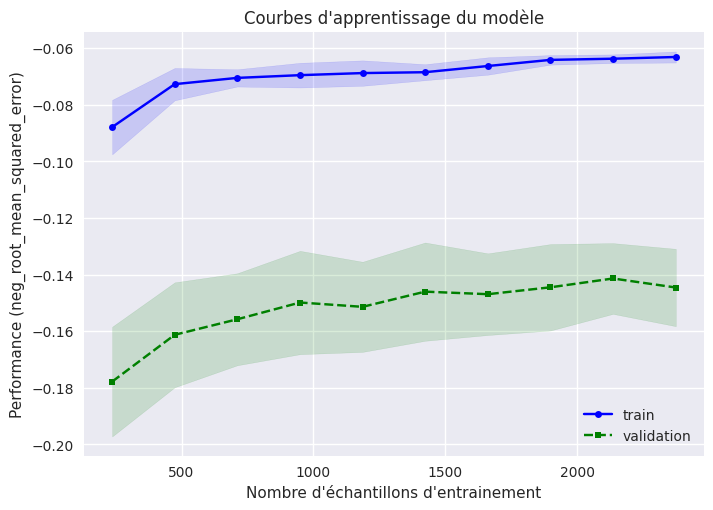


HISTOGRAMMES TARGET


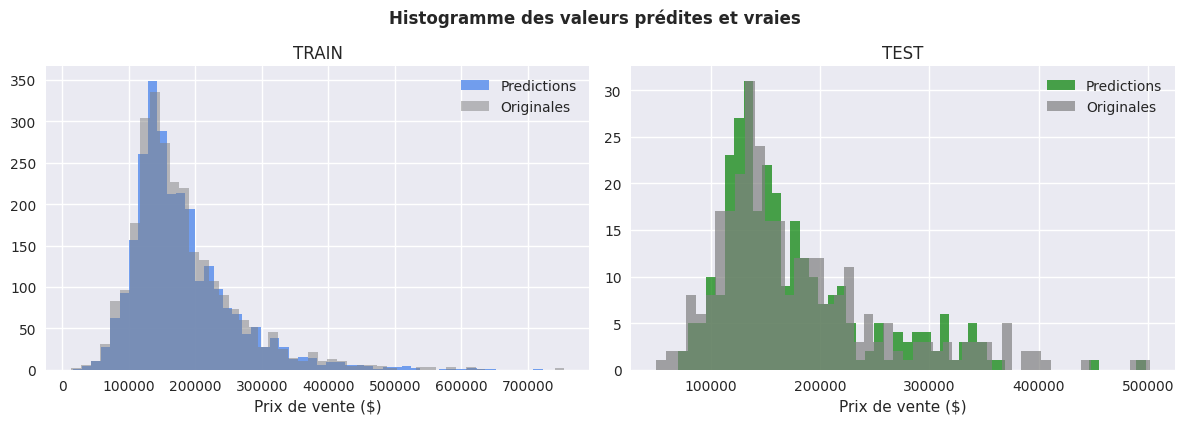

In [0]:
evaluate_log_model(rf0, X_train, y_train, cv=CV_STRATEGY)

>**Constat** : On estime que la performance en train avec un RMSLE = 0.060, soit une erreur médiane de 4,183$ est supposée suffisante ici (pas d'underfit). Par contre la performance par cross validation montre une situation d'**overfit**, plus de 10,000$ pour l'erreur médiane et un **RMSLE = 0.144** que l'on retiendra comme valeur de référence pour la suite.

In [0]:
_ = evaluate_final_test(rf0, X_test, y_test)

DONNÉES DE TEST — ÉVALUATION FINALE
  R²                       : 0.898
  RMSLE                    : 0.131
  MedAE                    : $11,052
  Erreur médiane relative  : 6.6%


#### premier réglage (manuel)
- construction d'un nouveau modèle visant à réduire cet overfit en limitant par exemple la poussée sans limite des arbres par défaut (paramètre : *max_depth*)

ENTRAÎNEMENT — modèle ajusté sur toutes les données d'entraînement
  R²                       : 0.895
  RMSLE                    : 0.136
  MedAE                    : $12,262
  Erreur médiane relative  : 7.6%

VALIDATION CROISÉE — métriques calculées dans l’espace réel
  R²                       : 0.861 +/- 0.032
  RMSLE                    : 0.159 +/- 0.013
  MedAE                    : $12,704 +/- $731
  Erreur médiane relative  : 8.0% +/- 0.6%

COURBES D’APPRENTISSAGE


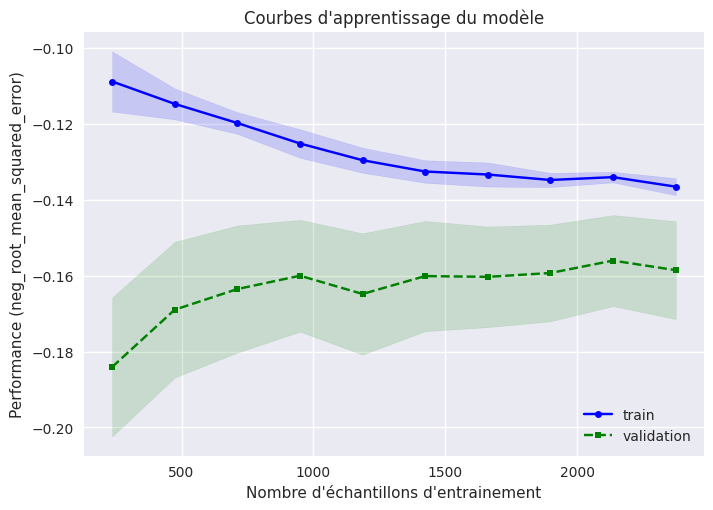


HISTOGRAMMES TARGET


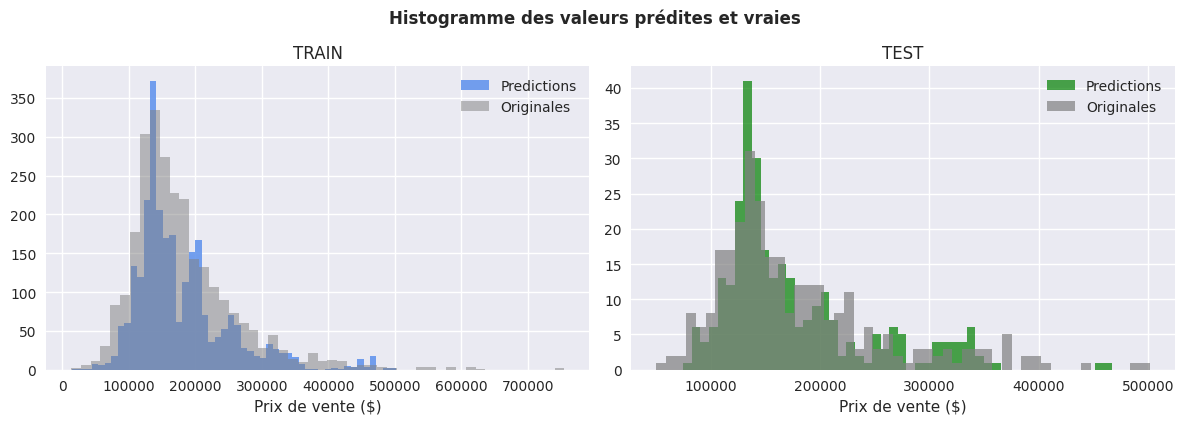

In [0]:
rf1 = make_model_pipeline(
    RandomForestRegressor(
        n_estimators=10,
        max_depth=5,
        random_state=1,
        n_jobs=16
    )
)
rf1.fit(X_train, y_train_log)

evaluate_log_model(rf1, X_train, y_train, cv=CV_STRATEGY)

> **Constat** : Sortie de l'overfit mais situation d'underfit maintenant

### grid search

- Dans un premier temps, un grid search peut aider à cerner le champs des possibles. Il s'agit ici de ne pas faire exploser la combinatoire car par définition le gridsearch va évaluer chacune des combinaisons.

> **stratégie** : on va chercher à relacher la contrainte sur la profondeur tout en contrôlant la pousse individuelle des branches avec le paramètre *min_impurity_decrease*

In [0]:
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, ParameterGrid


# n_estimators est fixé à une valeur suffisamment élevée pour stabiliser
# la forêt. La recherche porte sur la complexité de chaque arbre.
parameters = {
    'model__max_depth': [5, 10, 15, 20],
    'model__min_samples_leaf': [1, 5, 10]
}

n_candidates = len(ParameterGrid(parameters))
n_cv_splits = CV_STRATEGY.get_n_splits()
n_search_tasks = n_candidates * n_cv_splits

# Les tâches configuration × pli sont parallélisées.
N_JOBS_SEARCH = min(N_CORES, n_search_tasks)

rf_grid = make_model_pipeline(
    RandomForestRegressor(
        n_estimators=10,
        max_features=1.0,
        random_state=1,
        n_jobs=1
    )
)

print(
    f"Grid Search : {n_candidates} configurations × "
    f"{n_cv_splits} plis = {n_search_tasks} ajustements"
)
print(
    f"Nombre maximal d'ajustements simultanés : "
    f"{N_JOBS_SEARCH}",
    flush=True
)

rf_grid_cv = GridSearchCV(
    estimator=rf_grid,
    param_grid=parameters,
    scoring=PRIMARY_SCORING,
    cv=CV_STRATEGY,
    n_jobs=N_JOBS_SEARCH,
    pre_dispatch=N_JOBS_SEARCH,
    refit=False,
    return_train_score=True,
    verbose=10
)

rf_grid_cv.fit(X_train, y_train_log)

print(f"\nMeilleur réglage : {rf_grid_cv.best_params_}")
print(
    "RMSLE moyenne en validation croisée : "
    f"{-rf_grid_cv.best_score_:.4f}"
)

Grid Search : 12 configurations × 10 plis = 120 ajustements
Nombre maximal d'ajustements simultanés : 16
Fitting 10 folds for each of 12 candidates, totalling 120 fits

Meilleur réglage : {'model__max_depth': 10, 'model__min_samples_leaf': 1}
RMSLE moyenne en validation croisée : 0.1428


> **Constat** : le Grid Search réduit la RMSLE moyenne de 0,159 à 0.1428, en limitant la profondeur à 10 sans imposer de contrainte supplémentaire sur la taille des feuilles (min_samples_leaf=1). L'underfit se réduit mais on retombe dans l'overfit avec une petite réduction cependant de la RMSLE par rapport au modèle de référence (0.144)

### randomized search

> *Stratégie* : on va ajouter un nouveau paramètre de réduction d'overfit

In [0]:
from sklearn.model_selection import RandomizedSearchCV

parameters = {
    'model__min_impurity_decrease': [1e-5, 5e-5, 1e-4, 1e-3],
    'model__max_depth': [10, 15, 20, 25, 30],
    'model__min_samples_leaf': [1, 3, 5, 10]
}

print('Nombre de combinaison possible : ', len(ParameterGrid(parameters)) )

rf_rand = make_model_pipeline(
    RandomForestRegressor(n_estimators=10, random_state=1, n_jobs=N_JOBS_MODEL)
)

rf_rand_cv = RandomizedSearchCV(
    rf_rand,
    parameters,
    n_iter=10,
    n_jobs=N_JOBS_CV,
    scoring=PRIMARY_SCORING,
    cv=CV_STRATEGY,
    random_state=1,
    verbose=3
)
rf_rand_cv.fit(X_train, y_train_log)

print(f"\nMeilleur réglage : {rf_rand_cv.best_params_}")
print(
    "RMSLE moyenne en validation croisée : "
    f"{-rf_rand_cv.best_score_:.4f}"
)

Nombre de combinaison possible :  80
Fitting 10 folds for each of 10 candidates, totalling 100 fits
[CV 6/10] END model__max_depth=10, model__max_features=0.5, model__min_impurity_decrease=0.001, model__min_samples_leaf=1, model__min_samples_split=3;, score=-0.178 total time=   0.2s
[CV 3/10] END model__max_depth=30, model__max_features=0.7, model__min_impurity_decrease=5e-05, model__min_samples_leaf=1, model__min_samples_split=10;, score=-0.139 total time=   0.8s
[CV 3/10] END model__max_depth=15, model__max_features=0.5, model__min_impurity_decrease=0.001, model__min_samples_leaf=3, model__min_samples_split=2;, score=-0.164 total time=   0.2s
[CV 8/10] END model__max_depth=15, model__max_features=0.5, model__min_impurity_decrease=0.001, model__min_samples_leaf=3, model__min_samples_split=2;, score=-0.165 total time=   0.2s
[CV 4/10] END model__max_depth=15, model__max_features=0.5, model__min_impurity_decrease=1e-05, model__min_samples_leaf=1, model__min_samples_split=5;, score=-0.16

> **Constat** : Pas mieux !

### bayesian search

> *Stratégie* : on va élargir à deus autres hyper paramètres intéressants pour la réduction de l'overfit, les *max_sample* et *max_features* qui régissent l'aléatoire dans ce modèle

#### utilitaires

- imports utiles

In [0]:
from skopt.space import Real, Integer, Categorical
from skopt.utils import use_named_args
from skopt import gp_minimize
from skopt.plots import plot_convergence

- cross validation

In [0]:
# CV_STRATEGY a été définie avant tout réglage et est réutilisée partout.
CV_STRATEGY

KFold(n_splits=10, random_state=1, shuffle=True)

- fonction d'affichage

In [0]:
def show_gp_results(res_gp):
    score = f'{res_gp.fun:.3f}'
    print("- Best score : ", score)
    
    best_params = []
    for col, val in zip(res_gp.space.dimension_names,res_gp.x):
        best_params.append(f'{col} : {val}')
    print('- Best params : \n', best_params)
    
    print('')
    with plt.style.context('seaborn-v0_8'):
        plot_convergence(res_gp)
        plt.grid()
        display(plt.gcf())
        plt.close()
    return score, best_params

- gestion de la parallélisation

> Le parallélisme est défini une seule fois au début du notebook. Chaque modèle utilise un seul cœur (`N_JOBS_MODEL=1`) et la validation croisée parallélise au plus un entraînement par pli avec `N_JOBS_CV=min(CV_FOLDS, N_CORES)`. L'optimisation de la fonction d'acquisition utilise les cœurs disponibles via `N_JOBS_GP`.

#### run

> **Note** : on s'autorise ici d'explorer une augmentation du nombre d'arbres par rapport aux 10 maximum utilisés depuis le début. En effet pour les random forests, augmenter le nombre d'arbre ne signifie pas forcément un risque supplémentaire d'overfit. C'est davantage la régularisation des paramètres qui régissent leur poussée qui est clé.

Iteration No: 1 started. Evaluating function at random point.
Iteration No: 1 ended. Evaluation done at random point.
Time taken: 2.6204
Function value obtained: 0.1580
Current minimum: 0.1580
Iteration No: 2 started. Evaluating function at random point.
Iteration No: 2 ended. Evaluation done at random point.
Time taken: 0.8160
Function value obtained: 0.1625
Current minimum: 0.1580
Iteration No: 3 started. Evaluating function at random point.
Iteration No: 3 ended. Evaluation done at random point.
Time taken: 0.9619
Function value obtained: 0.1554
Current minimum: 0.1554
Iteration No: 4 started. Evaluating function at random point.
Iteration No: 4 ended. Evaluation done at random point.
Time taken: 0.6765
Function value obtained: 0.1587
Current minimum: 0.1554
Iteration No: 5 started. Evaluating function at random point.
Iteration No: 5 ended. Evaluation done at random point.
Time taken: 0.7764
Function value obtained: 0.1562
Current minimum: 0.1554
Iteration No: 6 started. Evaluating

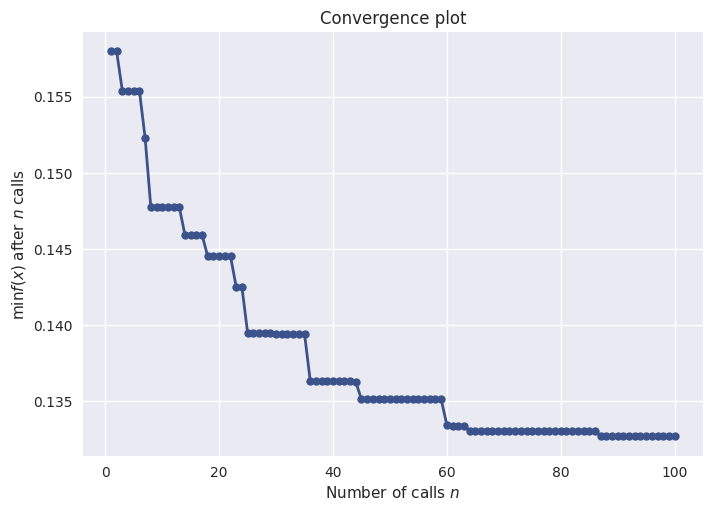

In [0]:
# instanciation du modèle de base
model = make_model_pipeline(
    RandomForestRegressor(random_state=1, n_jobs=N_JOBS_MODEL)
)

# définition des *espaces* de recherche
space = [
    Integer(10,100,   name='n_estimators'),
    Integer(2,30,   name='min_samples_split'),
    Integer(2,10,    name='max_depth'),
    Real(1e-6, 1.e-3,   name='min_impurity_decrease'),
    Real(1e-1, 1.,   name='max_features'),
    Real(1e-1, 1.,   name='max_samples'),
]

# définition de la fonction *objective* à minimiser
@use_named_args(space)
def objective(**params):
    model.set_params(**{f'model__{name}': value for name, value in params.items()})
    return -np.mean(cross_val_score(model, X_train, y_train_log, cv=CV_STRATEGY, n_jobs=N_JOBS_CV,
                                    scoring=PRIMARY_SCORING))

# lancement de l'optimisation bayésienne
res_gp1 = gp_minimize(objective, space, n_calls=100, random_state=0, n_jobs=N_JOBS_GP, verbose=True)

# Affichage des résultats
best_score, best_params = show_gp_results(res_gp1)


*Rq* = durée 11 minutes !!

>**Constat** : L'optimisation bayésienne sur le random forest conduit à une meilleure valeur du RMSLE qui se réduit à **0.133** ; réduction de 8% par rapport à la valeur de référence (0.144)

%md
*optionnel* :
```python
from sklearn.ensemble import RandomForestRegressor

best_params = {
    dim.name: value
    for dim, value in zip(space, res_gp.x)
}

best_rf_gp = make_model_pipeline(
    RandomForestRegressor(
        n_estimators=10,
        min_samples_split=best_params['min_samples_split'],
        max_depth=best_params['max_depth'],
        min_impurity_decrease=best_params['min_impurity_decrease'],
        max_features=best_params['max_features'],
        max_samples=best_params['max_samples'],
        bootstrap=True,
        random_state=1,
        n_jobs=N_JOBS_MODEL
    )
)
best_rf_gp.fit(X_train, y_train_log)
evaluate_log_model(best_rf_gp, X_train, y_train, cv=CV_STRATEGY)
```


## XGBoost

### run - bayesian search

- instanciation du modèle de base

In [0]:
from xgboost import XGBRegressor

model = make_model_pipeline(
    XGBRegressor(random_state=1, n_jobs=N_JOBS_MODEL)
)

- espaces de recherche

In [0]:
space = [
    Integer(10, 100,   name='n_estimators'),
    Real(1e-1, 1.,   name='gamma'),
    Integer(1, 10,   name='max_depth'),
    Real(0., 1.,    name='colsample_bytree'),
    Real(0., 0.1,    name='reg_alpha'),
    Real(0., 0.1,    name='reg_lambda'),
    Real(0.5, 1.,    name='subsample'),
    Real(0.01, 0.2,    name='learning_rate'),
]

- run

In [0]:
@use_named_args(space)
def objective(**params):
    model.set_params(**{f'model__{name}': value for name, value in params.items()})
    scores = cross_val_score(model, X_train, y_train_log, cv=CV_STRATEGY, n_jobs=N_JOBS_CV,
                             scoring=PRIMARY_SCORING)
    mean_score = -np.mean(scores)
    return mean_score if np.isfinite(mean_score) else 1.0

res_gp = gp_minimize(objective, space, n_calls=100, random_state=0, n_jobs=N_JOBS_GP, verbose=True)

Iteration No: 1 started. Evaluating function at random point.
Iteration No: 1 ended. Evaluation done at random point.
Time taken: 1.1341
Function value obtained: 0.1907
Current minimum: 0.1907
Iteration No: 2 started. Evaluating function at random point.
Iteration No: 2 ended. Evaluation done at random point.
Time taken: 0.2166
Function value obtained: 0.1373
Current minimum: 0.1373
Iteration No: 3 started. Evaluating function at random point.
Iteration No: 3 ended. Evaluation done at random point.
Time taken: 0.2099
Function value obtained: 0.1435
Current minimum: 0.1373
Iteration No: 4 started. Evaluating function at random point.
Iteration No: 4 ended. Evaluation done at random point.
Time taken: 0.2523
Function value obtained: 0.1388
Current minimum: 0.1373
Iteration No: 5 started. Evaluating function at random point.
Iteration No: 5 ended. Evaluation done at random point.
Time taken: 0.1967
Function value obtained: 0.1450
Current minimum: 0.1373
Iteration No: 6 started. Evaluating

*Rq* : durée 4 minutes

- Best score :  0.123
- Best params : 
 ['n_estimators : 54', 'gamma : 0.1', 'max_depth : 5', 'colsample_bytree : 0.25947504615809547', 'reg_alpha : 0.0', 'reg_lambda : 0.08956670522941308', 'subsample : 1.0', 'learning_rate : 0.10970051830527829']



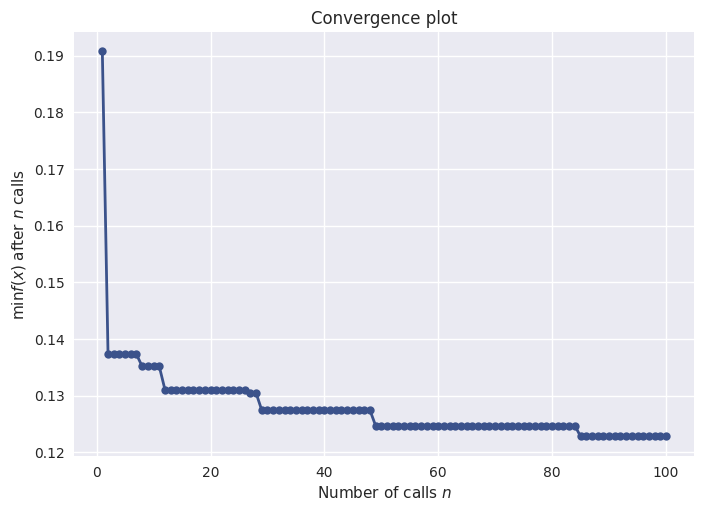

In [0]:
score_xgb, params_xgb = show_gp_results(res_gp)

> **Constat** : Meilleur résultat obtenu ici : **RMSLE = 0.123**, soit une réduction de 15% par rapport au modèle de référence (0.144)

### Affichage des perfomances complètes du modèle

ENTRAÎNEMENT — modèle ajusté sur toutes les données d'entraînement
  R²                       : 0.955
  RMSLE                    : 0.086
  MedAE                    : $8,000
  Erreur médiane relative  : 4.8%

VALIDATION CROISÉE — métriques calculées dans l’espace réel
  R²                       : 0.916 +/- 0.017
  RMSLE                    : 0.123 +/- 0.017
  MedAE                    : $9,504 +/- $663
  Erreur médiane relative  : 5.8% +/- 0.4%

COURBES D’APPRENTISSAGE


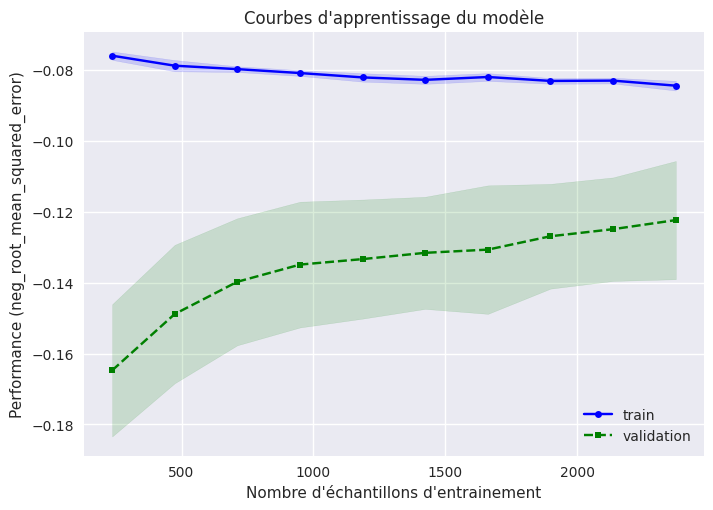


HISTOGRAMMES TARGET


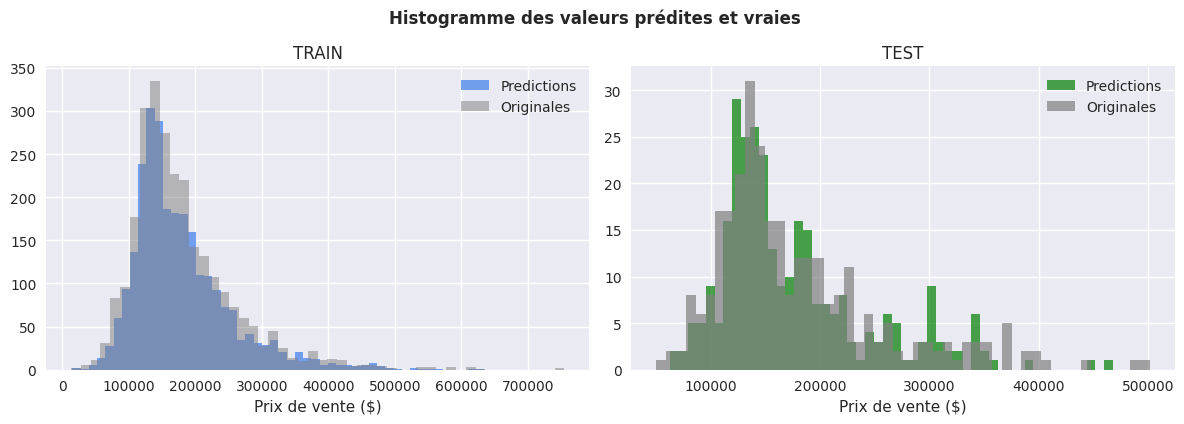

In [0]:
from xgboost import XGBRegressor

best_params = {
    dim.name: value
    for dim, value in zip(space, res_gp.x)
}

best_xgb_gp = make_model_pipeline(
    XGBRegressor(
        gamma=best_params['gamma'],
        n_estimators=best_params['n_estimators'],
        max_depth=best_params['max_depth'],
        colsample_bytree=best_params['colsample_bytree'],
        reg_alpha=best_params['reg_alpha'],
        reg_lambda=best_params['reg_lambda'],
        subsample=best_params['subsample'],
        learning_rate=best_params['learning_rate'],
        objective='reg:squarederror',
        random_state=1,
        n_jobs=N_JOBS_MODEL
    )
)
best_xgb_gp.fit(X_train, y_train_log)
evaluate_log_model(best_xgb_gp, X_train, y_train, cv=CV_STRATEGY)

In [0]:
_ = evaluate_final_test(best_xgb_gp, X_test, y_test)

DONNÉES DE TEST — ÉVALUATION FINALE
  R²                       : 0.924
  RMSLE                    : 0.110
  MedAE                    : $9,560
  Erreur médiane relative  : 5.8%


## Synthèse

### Comparaison des essais

Tous les réglages ont été sélectionnés à partir de la même validation croisée à 10 plis sur les données d'entraînement, avec la RMSLE comme critère principal.

| Essai | Meilleur réglage ou principe | RMSLE en validation croisée | Lecture |
|---|---|---:|---|
| Random Forest de référence | 10 arbres, paramètres par défaut | 0,144 ± 0,014 | Très bon ajustement sur l'entraînement (0,060), mais écart important avec la validation croisée : le modèle présente une forte variance. |
| Réglage manuel | `max_depth=3` | 0,159 ± 0,013 |La limitation est trop forte : l'écart entraînement-validation diminue, mais au prix d'un sous-apprentissage et d'une dégradation nette des performances. |
| Grid Search Random Forest | `max_depth=10`, `min_samples_leaf=1` | 0,1428 | Le compromis est meilleur que le réglage manuel, mais le gain par rapport à la référence reste inférieur à 1 %. La profondeur est limitée sans régularisation supplémentaire des feuilles. |
| Randomized Search Random Forest | `max_depth=30`, `min_samples_leaf=3`, `min_impurity_decrease=5e-5` | 0,1461 | Les 10 configurations tirées parmi 80 possibilités ne font pas mieux que la référence ; ce résultat ne démontre pas que la méthode aléatoire est moins pertinente, mais que ce budget et cet espace n'ont pas permis d'identifier un meilleur réglage. |
| Optimisation bayésienne Random Forest | 100 arbres, profondeur 10, `min_samples_split=2`, `max_features≈0,36`, `max_samples=1` | 0,1327 | Meilleur Random Forest en validation croisée, avec une réduction d'environ 8 % de la RMSLE par rapport à la référence. Plusieurs paramètres sont toutefois en bordure de l'espace de recherche, ce qui suggère qu'un élargissement ciblé pourrait encore être utile. |
| Optimisation bayésienne XGBoost | 54 arbres, profondeur 5, `learning_rate≈0,110`, `colsample_bytree≈0,26` | 0,123 ± 0,017 | Meilleur modèle de l'étude, avec une réduction d'environ 15 % de la RMSLE en validation croisée et de 16 % sur les données de test par rapport au Random Forest de référence. |


### Enseignements

1. **Une régularisation trop forte dégrade le modèle.** La profondeur 3 réduit l'écart entre entraînement et validation, mais supprime trop de signal et conduit à un sous-apprentissage.
2. **Les petites recherches ne suffisent pas nécessairement.** Le Grid Search apporte un gain marginal et le Randomized Search n'améliore pas la référence avec seulement 10 tirages. À l'inverse, l'optimisation bayésienne exploite mieux son budget de 100 évaluations.
3. **Le nombre d'arbres n'est pas le principal levier de régularisation du Random Forest.** Le meilleur réglage bayésien atteint la borne de 100 arbres ; leur augmentation stabilise surtout l'agrégation, tandis que la profondeur, la taille des feuilles et la sous-sélection des variables contrôlent davantage la variance.
4. **XGBoost offre le meilleur compromis biais-variance.** Son écart de RMSLE entre entraînement et validation est de 0,037 (0,086 contre 0,123), contre 0,084 pour le Random Forest de référence (0,060 contre 0,144). Il conserve donc une bonne capacité d'apprentissage tout en généralisant mieux.



### Choix final et portée métier

XGBoost est le choix prioritaire : sur les données de test, il atteint un R² de 0,924, une RMSLE de 0,110, une MedAE de 9 560 $ et une erreur médiane relative de 5,8 %. Par rapport au Random Forest de référence, il réduit l'erreur absolue typique de 1 492 $ et l'erreur relative médiane de 0,8 point, tout en expliquant une part plus importante de la variabilité des prix.

Le Random Forest bayésien reste une alternative intéressante si l'on privilégie un modèle d'ensemble plus simple à analyser, mais son avantage doit encore être confirmé sur les données de test après un réajustement complet.
